In [1]:
import pickle
from one.api import ONE
import pandas as pd
import SimpleITK as sitk
from brainwidemap import bwm_query, load_good_units, load_trials_and_mask, bwm_units

In [2]:
with open("all_units.pkl", "rb") as f:
    all_units = pickle.load(f)

all_units

[{'pid': '56f2a378-78d2-4132-b3c8-8c1ba82be598',
  'cluster_id': 2,
  'x': -0.002289,
  'y': -0.002537,
  'z': -0.003595,
  'atlas_id': 549,
  'spike_times': array([1280.17956115, 1308.40397292, 1408.93956308, ..., 4687.2943644 ,
         4688.31736358, 4688.35463022]),
  'spike_voltage': array([7.00786186e-05, 7.97781831e-05, 7.22701807e-05, ...,
         8.15545573e-05, 7.05181228e-05, 7.70979532e-05])},
 {'pid': '56f2a378-78d2-4132-b3c8-8c1ba82be598',
  'cluster_id': 15,
  'x': -0.002289,
  'y': -0.002533,
  'z': -0.003576,
  'atlas_id': 549,
  'spike_times': array([   7.27930925,   10.02560684,   10.05437348, ..., 4688.53469674,
         4688.60163002, 4688.63716332]),
  'spike_voltage': array([0.00033245, 0.00033308, 0.00031968, ..., 0.00031284, 0.00034012,
         0.00033704])},
 {'pid': '56f2a378-78d2-4132-b3c8-8c1ba82be598',
  'cluster_id': 22,
  'x': -0.002289,
  'y': -0.002528,
  'z': -0.003556,
  'atlas_id': 549,
  'spike_times': array([ 219.74047516,  556.91181808,  593.60

In [3]:
len(all_units)

75708

In [4]:
#one = ONE(base_url='https://openalyx.internationalbrainlab.org',password='international', mode='remote')
#unit_df = bwm_units(one)
#unit_df.to_csv('unit_df.csv', index=False) 
unit_df = pd.read_csv('unit_df.csv')
unit_df

,Beryl,eid,channels,depths,uuids,cluster_id,amp_max,amp_min,amp_median,amp_std_dB,...,ks2_label,x,y,z,acronym,atlas_id,axial_um,lateral_um,pid,spike_count_good
0,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,61,620.0,c5cabbda-1f74-4168-ad5e-7c5a2f533d9f,79,0.000300,0.000081,0.000158,1.056608,...,good,-0.002378,-0.000250,-0.006350,CNU,23,620.0,11.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,167762.0
1,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,68,700.0,5b5176f2-228f-46b5-85c8-205cf9d90a53,88,0.000323,0.000123,0.000221,0.972567,...,good,-0.002364,-0.000250,-0.006272,CNU,23,700.0,43.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,16139.0
2,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,71,720.0,19930b44-2f8a-44e1-a8ce-46184f7334cb,91,0.000187,0.000057,0.000109,1.266665,...,good,-0.002364,-0.000250,-0.006252,CNU,23,720.0,27.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,34700.0
3,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,77,780.0,304c2251-f207-4926-ba28-967ebbda4473,105,0.000208,0.000046,0.000079,1.655816,...,good,-0.002364,-0.000250,-0.006192,CNU,23,780.0,11.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,224475.0
4,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,82,840.0,4bd714b8-5753-4561-87e5-2ef3126426b7,115,0.000346,0.000085,0.000163,1.334542,...,good,-0.002364,-0.000250,-0.006132,CNU,23,840.0,59.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,292062.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62985,x,810b1e07-009e-4ebe-930a-915e4cd8ece4,55,560.0,3beabe91-423a-49c3-8e55-fb846457c89d,152,0.000258,0.000093,0.000139,1.890024,...,good,-0.001714,-0.006287,-0.004645,HB,765,560.0,27.0,c5fd185f-1c5a-4aad-9795-43c4ccf8ea94,2307.0
62986,x,810b1e07-009e-4ebe-930a-915e4cd8ece4,57,580.0,78952ffb-d419-464e-96e9-2b22723aa58b,158,0.000910,0.000085,0.000170,3.049439,...,good,-0.001725,-0.006281,-0.004621,HB,765,580.0,11.0,c5fd185f-1c5a-4aad-9795-43c4ccf8ea94,544566.0
62987,x,810b1e07-009e-4ebe-930a-915e4cd8ece4,54,560.0,2490ff61-baae-4e8e-a90e-d34e851b8cd1,160,0.000213,0.000069,0.000119,1.654493,...,good,-0.001714,-0.006287,-0.004645,HB,765,560.0,59.0,c5fd185f-1c5a-4aad-9795-43c4ccf8ea94,37240.0
62988,x,810b1e07-009e-4ebe-930a-915e4cd8ece4,58,600.0,945e9b3b-0a09-4272-b56e-7640e1e1f647,161,0.000247,0.000070,0.000109,1.398105,...,good,-0.001735,-0.006276,-0.004598,HB,765,600.0,59.0,c5fd185f-1c5a-4aad-9795-43c4ccf8ea94,37519.0


In [5]:
len(unit_df['eid'].unique())

454

In [6]:
from iblatlas.regions import BrainRegions
import pandas as pd

br = BrainRegions()

region_table = pd.DataFrame({
    'atlas_id': br.id,
    'acronym': br.acronym,
    'name': br.name,
    'level': br.level,
    'parent': br.parent,
    'order': br.order
})

region_table[:]

,atlas_id,acronym,name,level,parent,order
0,0,void,void,0,NaN,0
1,997,root,root,0,NaN,0
2,8,grey,Basic cell groups and regions,1,997.0,1
3,567,CH,Cerebrum,2,8.0,2
4,688,CTX,Cerebral cortex,3,567.0,3
...,...,...,...,...,...,...
2650,-49,ipf,intraparafloccular fissure (left),3,-1040.0,1322
2651,-57,pms,paramedian sulcus (left),3,-1040.0,1323
2652,-65,pfs,parafloccular sulcus (left),3,-1040.0,1324
2653,-624,IPF,Interpeduncular fossa (left),2,-1024.0,1325


In [7]:
region_table[region_table["level"]==5]

,atlas_id,acronym,name,level,parent,order
6,315,Isocortex,Isocortex,5,695.0,5
380,698,OLF,Olfactory areas,5,695.0,379
455,1089,HPF,Hippocampal formation,5,695.0,454
557,16,6b,Layer 6b isocortex,5,703.0,556
558,583,CLA,Claustrum,5,703.0,557
...,...,...,...,...,...,...
2614,-595,fr,fasciculus retroflexus (left),5,-1083.0,1286
2615,-611,hbc,habenular commissure (left),5,-1083.0,1287
2616,-730,PIS,pineal stalk (left),5,-1083.0,1288
2618,-547,dlf,dorsal longitudinal fascicle (left),5,-70.0,1290


In [8]:
atlas_id_to_acronym = dict(zip(region_table['atlas_id'], region_table['acronym']))
atlas_id_to_acronym

{0: 'void',
 997: 'root',
 8: 'grey',
 567: 'CH',
 688: 'CTX',
 695: 'CTXpl',
 315: 'Isocortex',
 184: 'FRP',
 68: 'FRP1',
 667: 'FRP2/3',
 526157192: 'FRP5',
 526157196: 'FRP6a',
 526322264: 'FRP6b',
 500: 'MO',
 107: 'MO1',
 219: 'MO2/3',
 299: 'MO5',
 644: 'MO6a',
 947: 'MO6b',
 985: 'MOp',
 320: 'MOp1',
 943: 'MOp2/3',
 648: 'MOp5',
 844: 'MOp6a',
 882: 'MOp6b',
 993: 'MOs',
 656: 'MOs1',
 962: 'MOs2/3',
 767: 'MOs5',
 1021: 'MOs6a',
 1085: 'MOs6b',
 453: 'SS',
 12993: 'SS1',
 12994: 'SS2/3',
 12995: 'SS4',
 12996: 'SS5',
 12997: 'SS6a',
 12998: 'SS6b',
 322: 'SSp',
 793: 'SSp1',
 346: 'SSp2/3',
 865: 'SSp4',
 921: 'SSp5',
 686: 'SSp6a',
 719: 'SSp6b',
 353: 'SSp-n',
 558: 'SSp-n1',
 838: 'SSp-n2/3',
 654: 'SSp-n4',
 702: 'SSp-n5',
 889: 'SSp-n6a',
 929: 'SSp-n6b',
 329: 'SSp-bfd',
 981: 'SSp-bfd1',
 201: 'SSp-bfd2/3',
 1047: 'SSp-bfd4',
 1070: 'SSp-bfd5',
 1038: 'SSp-bfd6a',
 1062: 'SSp-bfd6b',
 480149202: 'VISrll',
 480149206: 'VISrll1',
 480149210: 'VISrll2/3',
 480149214: 'VISr

In [9]:
len(atlas_id_to_acronym)

2655

In [10]:
len(unit_df["eid"].unique())

454

## 1. plot

In [11]:
import pandas as pd

valid_pairs = set(zip(unit_df["pid"], unit_df["cluster_id"]))

filtered_units = [
    unit for unit in all_units
    if (unit["pid"], unit["cluster_id"]) in valid_pairs
]

print(f"original counts: {len(all_units)}")
print(f"filtered counts: {len(filtered_units)}")

original counts: 75708
filtered counts: 62990


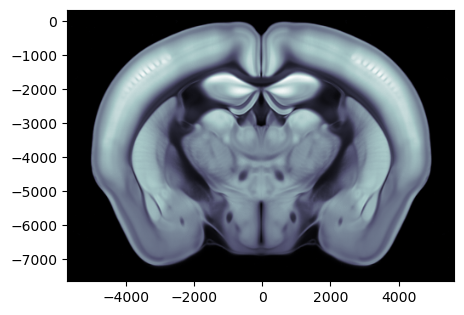

In [12]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25)
image_volume = atlas.image
label_volume = atlas.label

ap_coordinate = -1000 / 1e6  
fig, ax = plt.subplots(figsize=(5, 5))
atlas.plot_cslice(ap_coordinate, volume='image', ax=ax)
plt.show()

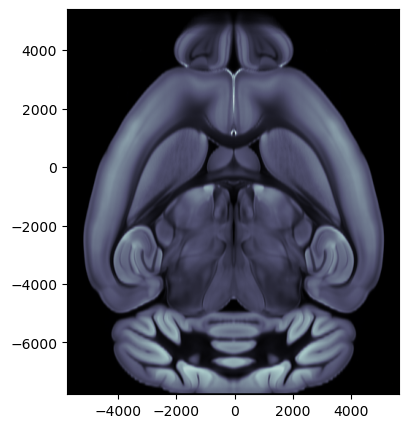

In [13]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25)

dv_coordinate = -3000 / 1e6  
fig, ax = plt.subplots(figsize=(5, 5))
atlas.plot_hslice(dv_coordinate, volume='image', ax=ax)
plt.show()

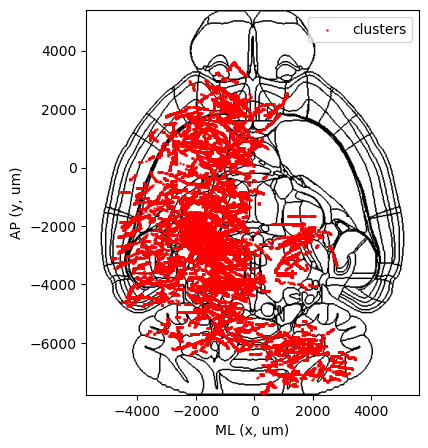

In [14]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25)

x_vals = [unit['x'] * 1e6 for unit in filtered_units]
y_vals = [unit['y'] * 1e6 for unit in filtered_units]
z_vals = [unit['z'] * 1e6 for unit in filtered_units]

dv_coordinate = -3500 / 1e6 

fig, ax = plt.subplots(figsize=(5, 5))
atlas.plot_hslice(dv_coordinate, volume='boundary', ax=ax)

ax.scatter(x_vals, y_vals, c='red', s=1, alpha=0.7, label="clusters")

ax.set_xlabel("ML (x, um)")
ax.set_ylabel("AP (y, um)")
ax.legend()
plt.savefig("./result/slice_plot.tiff", format="tif", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_1734386/3372309364.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


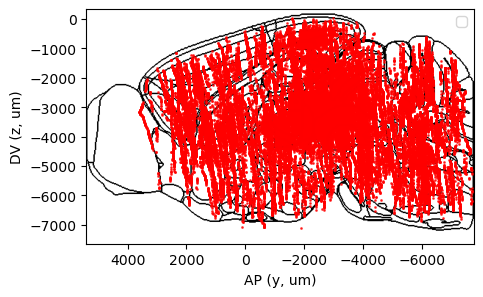

In [15]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25)

x_vals = [unit['x'] * 1e6 for unit in filtered_units]
y_vals = [unit['y'] * 1e6 for unit in filtered_units]
z_vals = [unit['z'] * 1e6 for unit in filtered_units]

ml_coordinate = -800 / 1e6  
fig, ax = plt.subplots(figsize=(5, 5))
atlas.plot_sslice(ml_coordinate, volume='boundary', ax=ax)

ax.scatter(y_vals, z_vals, c='red', s=1, alpha=0.7, label="")

ax.set_xlabel("AP (y, um)")
ax.set_ylabel("DV (z, um)")
ax.legend()
plt.savefig("./result/slice_plot2.tiff", format="tif", dpi=300, bbox_inches="tight")
plt.show()

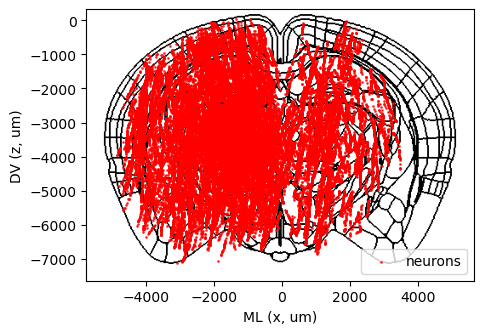

In [16]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25)

x_vals = [unit['x'] * 1e6 for unit in filtered_units]
y_vals = [unit['y'] * 1e6 for unit in filtered_units]
z_vals = [unit['z'] * 1e6 for unit in filtered_units]

ap_coordinate = -2000 / 1e6 

fig, ax = plt.subplots(figsize=(5, 5))
atlas.plot_cslice(ap_coordinate, volume='boundary', ax=ax)

ax.scatter(x_vals, z_vals, c='red', s=1, alpha=0.7, label="neurons")

ax.set_xlabel("ML (x, um)")
ax.set_ylabel("DV (z, um)")
ax.legend()
plt.show()

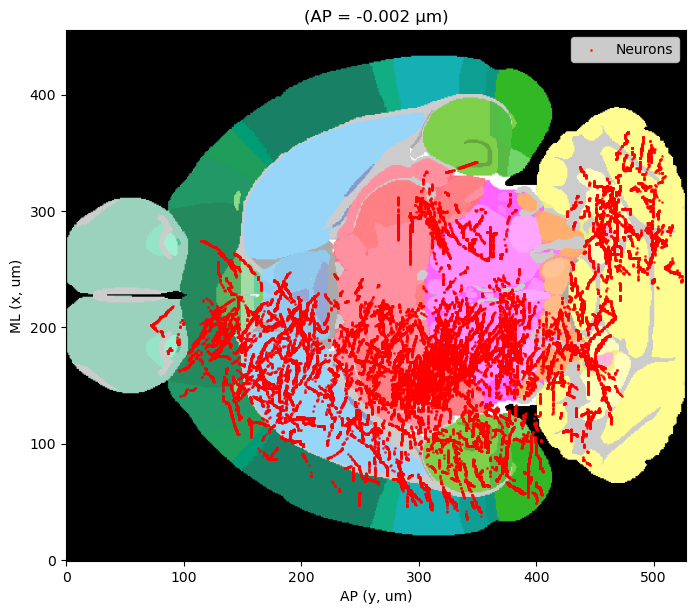

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25) #y,x,z (528,456,320)

ccf_coords = []
for unit in filtered_units:
    x, y, z = unit['x'], unit['y'], unit['z']
    ccf = atlas.xyz2ccf(np.array([[x, y, z]])) 
    ccf_coords.append(ccf[0])  

dv_coordinate = 160  

img1 = sitk.ReadImage("../ccf-v3/annotation_25_recolor.nrrd")   #x,z,y (456, 320, 528)
array1 = sitk.GetArrayFromImage(img1)

fig, ax = plt.subplots(figsize=(8, 6.89))

rotated_image = np.rot90(array1[:, dv_coordinate, :], k=0)  # k=3 for 90 degrees clockwise rotation
plt.imshow(rotated_image, cmap='gray', aspect='auto')

x_vals = [coord[1] / 25 for coord in ccf_coords]  
y_vals = [coord[0] / 25 for coord in ccf_coords]  # CCF y 坐标
ax.scatter(x_vals, y_vals, c='red', s=1, alpha=0.7, label="Neurons")
ax.invert_yaxis()

ax.set_xlabel("AP (y, um)")
ax.set_ylabel("ML (x, um)")
ax.set_title(f"(AP = {ap_coordinate} μm)")
ax.legend()

plt.show()

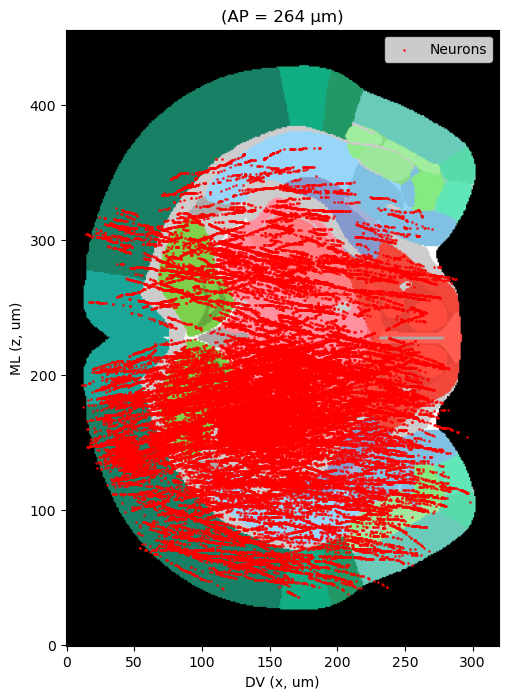

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25) #y,x,z (528,456,320)

ccf_coords = []
for unit in filtered_units:
    x, y, z = unit['x'], unit['y'], unit['z']
    ccf = atlas.xyz2ccf(np.array([[x, y, z]])) 
    ccf_coords.append(ccf[0])  

ap_coordinate = 264 

img1 = sitk.ReadImage("../ccf-v3/annotation_25_recolor.nrrd")   #x,z,y (456, 320, 528)
array1 = sitk.GetArrayFromImage(img1)

fig, ax = plt.subplots(figsize=(5.59, 8))

rotated_image = np.rot90(array1[:, :, ap_coordinate], k=0)  # k=3 for 90 degrees clockwise rotation
plt.imshow(rotated_image, cmap='gray', aspect='auto')

x_vals = [coord[2] / 25 for coord in ccf_coords]  
z_vals = [coord[0] / 25 for coord in ccf_coords]  # CCF y 坐标
ax.scatter(x_vals, z_vals, c='red', s=1, alpha=0.7, label="Neurons")
ax.invert_yaxis()

ax.set_xlabel("DV (x, um)")
ax.set_ylabel("ML (z, um)")
ax.set_title(f"(AP = {ap_coordinate} μm)")
ax.legend()


plt.show()

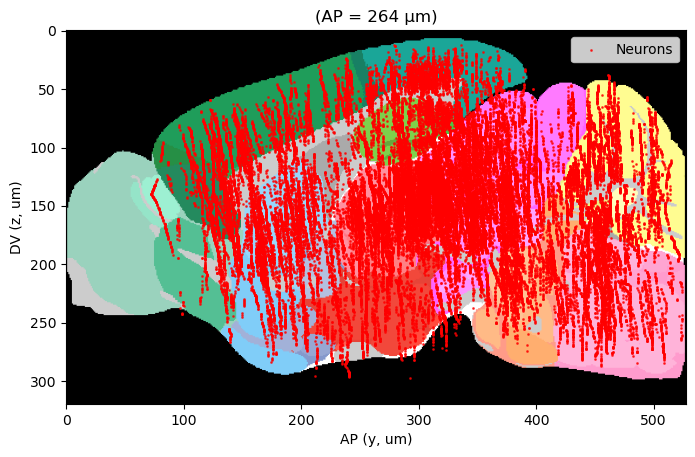

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25) #y,x,z (528,456,320)

ccf_coords = []
for unit in filtered_units:
    x, y, z = unit['x'], unit['y'], unit['z']
    ccf = atlas.xyz2ccf(np.array([[x, y, z]])) 
    ccf_coords.append(ccf[0])  

ml_coordinate = 273

img1 = sitk.ReadImage("../ccf-v3/annotation_25_recolor.nrrd")   #x,z,y (456, 320, 528)
array1 = sitk.GetArrayFromImage(img1)

fig, ax = plt.subplots(figsize=(8, 4.85))

rotated_image = np.rot90(array1[ml_coordinate, :, :], k=0)  # k=3 for 90 degrees clockwise rotation
plt.imshow(rotated_image, cmap='gray', aspect='auto')

y_vals = [coord[1] / 25 for coord in ccf_coords]  
z_vals = [coord[2] / 25 for coord in ccf_coords]  # CCF y 坐标
ax.scatter(y_vals, z_vals, c='red', s=1, alpha=0.7, label="Neurons")
#ax.invert_yaxis()

ax.set_xlabel("AP (y, um)")
ax.set_ylabel("DV (z, um)")
ax.set_title(f"(AP = {ap_coordinate} μm)")
ax.legend()

plt.show()

## 2. SC

In [20]:
df_layers = pd.read_excel('SEU_net_w_corticalLayers.xlsx', header=1, index_col=1)
df_layers = df_layers.iloc[:, 1:]
df_layers

,FRP2/3,MOp1,MOp2/3,MOp5,MOp6a,MOs1,MOs2/3,MOs5,MOs6a,SSp-n2/3,...,MD,SMT,PVT,RE,CM,RT,PSV,PB,TRN,PRNr
FRP2/3,0.000000,0.0,0.000000,0.000000,0.000000,0.835160,2.300365,1.791165,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000
MOp1,0.000000,0.0,1.435472,2.390881,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000
MOp2/3,0.625221,0.0,2.078293,2.099848,1.924731,0.715541,1.498042,1.575019,0.0,0.426072,...,0.000000,0.00000,0.0,0.000000,0.0,0.932975,0,0,0,0.875238
MOp5,0.000000,0.0,1.068048,3.553463,1.668447,0.409365,2.183911,2.279111,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.794181,0,0,0,0.000000
MOp6a,0.000000,0.0,2.304936,0.488099,2.354786,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.917643,0,0,0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,1.514522,2.13142,0.0,4.582369,0.0,0.762490,0,0,0,0.000000
PSV,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.000000,0,0,0,0.720976
PB,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.000000,0,0,0,1.214098
TRN,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000


In [21]:
df_nolayers = pd.read_excel('SEU_net_wo_corticalLayers.xlsx', header=1, index_col=1)
df_nolayers = df_nolayers.iloc[:, 1:]
df_nolayers

,FRP,MOp,MOs,SSp-n,SSp-bfd,SSp-ll,SSp-m,SSp-ul,SSp-tr,SSp-un,...,MD,SMT,PVT,RE,CM,RT,PSV,PB,TRN,PRNr
FRP,0.000000,0.000000,2.028292,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000
MOp,0.625221,1.992551,1.765525,0.930700,0.678581,1.968629,1.024268,0.953173,1.600363,0.961477,...,0.000000,0.000000,0.0,0.000000,0.0,0.861023,0,0,0,0.875238
MOs,1.417198,1.381516,1.645074,0.670320,2.725806,0.853611,1.209884,1.446972,0.000000,0.000000,...,0.000000,1.621683,0.0,0.000000,0.0,0.768877,0,0,0,0.000000
SSp-n,0.000000,0.789537,1.283165,1.795210,1.301726,0.000000,1.947067,2.399795,0.000000,1.158404,...,0.000000,0.000000,0.0,0.000000,0.0,0.810396,0,0,0,0.000000
SSp-bfd,0.000000,1.159698,0.766737,1.669994,1.934520,0.447926,1.166723,0.869816,3.467967,1.047941,...,0.000000,0.000000,0.0,0.000000,0.0,0.191446,0,0,0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.514522,2.131420,0.0,4.582369,0.0,0.762490,0,0,0,0.000000
PSV,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.720976
PB,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,1.214098
TRN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000


In [22]:
import pickle
import numpy as np

eligible_eids = sorted(set(unit_df['eid'].dropna()))

SPLIT_SEED = 22
rng = np.random.default_rng(SPLIT_SEED)

eids = np.array(eligible_eids, dtype=object)
rng.shuffle(eids)

n = len(eids) // 2

subset_A_eids = set(eids[:n])
subset_B_eids = set(eids[n:])

assert subset_A_eids.isdisjoint(subset_B_eids)
assert subset_A_eids | subset_B_eids == set(eligible_eids)

with open(f'session_split_seed{SPLIT_SEED}.pkl', 'wb') as f:
    pickle.dump({
        'seed': SPLIT_SEED,
        'subset_A_eids': list(subset_A_eids),
        'subset_B_eids': list(subset_B_eids)
    }, f)

print(
    f"Total={len(eids)}, "
    f"A={len(subset_A_eids)}, "
    f"B={len(subset_B_eids)}"
)

Total=454, A=227, B=227


In [ ]:
import pickle
import numpy as np
import pandas as pd
from collections import defaultdict, deque

with open('eid_to_trials.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)

with open('session_split_seed42.pkl', 'rb') as f:
    split = pickle.load(f)

subset_A_eids = set(split['subset_A_eids'])
subset_B_eids = set(split['subset_B_eids'])

region_table = region_table.copy()
region_table['parent'] = region_table['parent'].replace({None: np.nan})

id_to_acronym = dict(zip(region_table['atlas_id'], region_table['acronym']))
acronym_to_id = dict(zip(region_table['acronym'], region_table['atlas_id']))

children_map = defaultdict(list)
for _, row in region_table.iterrows():
    if not pd.isna(row['parent']):
        children_map[int(row['parent'])].append(int(row['atlas_id']))


def get_descendant_acronyms(parent_acronym):
    if parent_acronym not in acronym_to_id:
        return []

    out = []
    dq = deque([int(acronym_to_id[parent_acronym])])

    while dq:
        cur = dq.popleft()
        if cur in id_to_acronym:
            out.append(id_to_acronym[cur])
        dq.extend(children_map.get(cur, []))

    return out


target_parents = list(df_nolayers.index.astype(str))
all_target_acronyms = set()
map_child_to_parent = {}

for parent in target_parents:
    for child in get_descendant_acronyms(parent):
        all_target_acronyms.add(child)
        map_child_to_parent[child] = parent


brain_region_data = {
    'A': defaultdict(list),
    'B': defaultdict(list)
}

for unit in all_units:

    region_id = unit['atlas_id']

    if region_id not in id_to_acronym:
        continue

    acronym = id_to_acronym[region_id]

    if acronym not in all_target_acronyms:
        continue

    matched = unit_df[
        (unit_df['pid'] == unit['pid']) &
        (unit_df['cluster_id'] == unit['cluster_id'])
    ]

    if matched.empty:
        continue

    eid = matched['eid'].values[0]
    trials = eid_to_trials.get(eid, [])

    if len(trials) == 0:
        continue

    if eid in subset_A_eids:
        group = 'A'
    elif eid in subset_B_eids:
        group = 'B'
    else:
        continue

    region = map_child_to_parent.get(acronym, acronym)

    for trial_start, trial_end in trials:

        if trial_end <= trial_start:
            continue

        mask = (
            (unit['spike_times'] >= trial_start) &
            (unit['spike_times'] <= trial_end)
        )

        if not np.any(mask):
            continue

        spike_times_std = (
            unit['spike_times'][mask] - trial_start
        ) / (trial_end - trial_start)

        brain_region_data[group][region].append({
            'spike_times': spike_times_std,
            'spike_voltages': unit['spike_voltage'][mask]
        })


def merge_regions(data):
    out = {}

    for region, items in data.items():

        times = np.concatenate([x['spike_times'] for x in items])
        volts = np.concatenate([x['spike_voltages'] for x in items])

        idx = np.argsort(times)

        out[region] = {
            'spike_times': times[idx],
            'spike_voltages': volts[idx]
        }

    return out


for group in ['A', 'B']:

    result = merge_regions(brain_region_data[group])

    with open(
        f'brain_region_wo_layer_stage1_subset{group}_seed{SPLIT_SEED}.pkl',
        'wb'
    ) as f:
        pickle.dump(result, f)

    print(
        f"Subset {group}: "
        f"{len(result)} regions"
    )

In [ ]:
import pickle
import numpy as np
import pandas as pd
from collections import defaultdict, deque

with open('eid_to_trials_firstMovement2response.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)

with open('session_split_seed42.pkl', 'rb') as f:
    split = pickle.load(f)

subset_A_eids = set(split['subset_A_eids'])
subset_B_eids = set(split['subset_B_eids'])

region_table = region_table.copy()
region_table['parent'] = region_table['parent'].replace({None: np.nan})

id_to_acronym = dict(zip(region_table['atlas_id'], region_table['acronym']))
acronym_to_id = dict(zip(region_table['acronym'], region_table['atlas_id']))

children_map = defaultdict(list)
for _, row in region_table.iterrows():
    if not pd.isna(row['parent']):
        children_map[int(row['parent'])].append(int(row['atlas_id']))


def get_descendant_acronyms(parent_acronym):
    if parent_acronym not in acronym_to_id:
        return []

    out = []
    dq = deque([int(acronym_to_id[parent_acronym])])

    while dq:
        cur = dq.popleft()
        if cur in id_to_acronym:
            out.append(id_to_acronym[cur])
        dq.extend(children_map.get(cur, []))

    return out


target_parents = list(df_nolayers.index.astype(str))
all_target_acronyms = set()
map_child_to_parent = {}

for parent in target_parents:
    for child in get_descendant_acronyms(parent):
        all_target_acronyms.add(child)
        map_child_to_parent[child] = parent


brain_region_data = {
    'A': defaultdict(list),
    'B': defaultdict(list)
}

for unit in all_units:

    region_id = unit['atlas_id']

    if region_id not in id_to_acronym:
        continue

    acronym = id_to_acronym[region_id]

    if acronym not in all_target_acronyms:
        continue

    matched = unit_df[
        (unit_df['pid'] == unit['pid']) &
        (unit_df['cluster_id'] == unit['cluster_id'])
    ]

    if matched.empty:
        continue

    eid = matched['eid'].values[0]
    trials = eid_to_trials.get(eid, [])

    if len(trials) == 0:
        continue

    if eid in subset_A_eids:
        group = 'A'
    elif eid in subset_B_eids:
        group = 'B'
    else:
        continue

    region = map_child_to_parent.get(acronym, acronym)

    for trial_start, trial_end in trials:

        if trial_end <= trial_start:
            continue

        mask = (
            (unit['spike_times'] >= trial_start) &
            (unit['spike_times'] <= trial_end)
        )

        if not np.any(mask):
            continue

        spike_times_std = (
            unit['spike_times'][mask] - trial_start
        ) / (trial_end - trial_start)

        brain_region_data[group][region].append({
            'spike_times': spike_times_std,
            'spike_voltages': unit['spike_voltage'][mask]
        })


def merge_regions(data):
    out = {}

    for region, items in data.items():

        times = np.concatenate([x['spike_times'] for x in items])
        volts = np.concatenate([x['spike_voltages'] for x in items])

        idx = np.argsort(times)

        out[region] = {
            'spike_times': times[idx],
            'spike_voltages': volts[idx]
        }

    return out


for group in ['A', 'B']:

    result = merge_regions(brain_region_data[group])

    with open(
        f'brain_region_wo_layer_stage2_subset{group}_seed{SPLIT_SEED}.pkl',
        'wb'
    ) as f:
        pickle.dump(result, f)

    print(
        f"Subset {group}: "
        f"{len(result)} regions"
    )

In [ ]:
import pickle
import numpy as np
import pandas as pd
from collections import defaultdict, deque

with open('eid_to_trials_feedback2intervals1.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)

with open('session_split_seed42.pkl', 'rb') as f:
    split = pickle.load(f)

subset_A_eids = set(split['subset_A_eids'])
subset_B_eids = set(split['subset_B_eids'])

region_table = region_table.copy()
region_table['parent'] = region_table['parent'].replace({None: np.nan})

id_to_acronym = dict(zip(region_table['atlas_id'], region_table['acronym']))
acronym_to_id = dict(zip(region_table['acronym'], region_table['atlas_id']))

children_map = defaultdict(list)
for _, row in region_table.iterrows():
    if not pd.isna(row['parent']):
        children_map[int(row['parent'])].append(int(row['atlas_id']))


def get_descendant_acronyms(parent_acronym):
    if parent_acronym not in acronym_to_id:
        return []

    out = []
    dq = deque([int(acronym_to_id[parent_acronym])])

    while dq:
        cur = dq.popleft()
        if cur in id_to_acronym:
            out.append(id_to_acronym[cur])
        dq.extend(children_map.get(cur, []))

    return out


target_parents = list(df_nolayers.index.astype(str))
all_target_acronyms = set()
map_child_to_parent = {}

for parent in target_parents:
    for child in get_descendant_acronyms(parent):
        all_target_acronyms.add(child)
        map_child_to_parent[child] = parent


brain_region_data = {
    'A': defaultdict(list),
    'B': defaultdict(list)
}

for unit in all_units:

    region_id = unit['atlas_id']

    if region_id not in id_to_acronym:
        continue

    acronym = id_to_acronym[region_id]

    if acronym not in all_target_acronyms:
        continue

    matched = unit_df[
        (unit_df['pid'] == unit['pid']) &
        (unit_df['cluster_id'] == unit['cluster_id'])
    ]

    if matched.empty:
        continue

    eid = matched['eid'].values[0]
    trials = eid_to_trials.get(eid, [])

    if len(trials) == 0:
        continue

    if eid in subset_A_eids:
        group = 'A'
    elif eid in subset_B_eids:
        group = 'B'
    else:
        continue

    region = map_child_to_parent.get(acronym, acronym)

    for trial_start, trial_end in trials:

        if trial_end <= trial_start:
            continue

        mask = (
            (unit['spike_times'] >= trial_start) &
            (unit['spike_times'] <= trial_end)
        )

        if not np.any(mask):
            continue

        spike_times_std = (
            unit['spike_times'][mask] - trial_start
        ) / (trial_end - trial_start)

        brain_region_data[group][region].append({
            'spike_times': spike_times_std,
            'spike_voltages': unit['spike_voltage'][mask]
        })


def merge_regions(data):
    out = {}

    for region, items in data.items():

        times = np.concatenate([x['spike_times'] for x in items])
        volts = np.concatenate([x['spike_voltages'] for x in items])

        idx = np.argsort(times)

        out[region] = {
            'spike_times': times[idx],
            'spike_voltages': volts[idx]
        }

    return out


for group in ['A', 'B']:

    result = merge_regions(brain_region_data[group])

    with open(
        f'brain_region_wo_layer_stage3_subset{group}_seed{SPLIT_SEED}.pkl',
        'wb'
    ) as f:
        pickle.dump(result, f)

    print(
        f"Subset {group}: "
        f"{len(result)} regions"
    )

In [ ]:
import pickle, os
import numpy as np
import pandas as pd

stages = [1, 2, 3]
groups = ['A', 'B']
diff_threshold = 0.25

files = {
    (s, g): f'brain_region_wo_layer_stage{s}_subset{g}_seed{SPLIT_SEED}.pkl'
    for s in stages for g in groups
}

data = {}
for k, f in files.items():
    if not os.path.exists(f):
        raise FileNotFoundError(f)
    with open(f, 'rb') as x:
        data[k] = pickle.load(x)

common = set.intersection(*[set(d.keys()) for d in data.values()])
region_order = [r for r in df_nolayers.index.astype(str) if r in common]

scores = {}
details = {}

for r in region_order:
    vals = []
    details[r] = {}

    for s in stages:
        nA = len(data[(s, 'A')][r]['spike_times'])
        nB = len(data[(s, 'B')][r]['spike_times'])
        score = abs(nA - nB) / (nA + nB) if (nA + nB) > 0 else np.inf

        vals.append(score)
        details[r][f'stage{s}_A'] = nA
        details[r][f'stage{s}_B'] = nB
        details[r][f'stage{s}_diff'] = score

    scores[r] = np.mean(vals)

ranked = sorted(region_order, key=lambda r: scores[r])
keep = {r for r in ranked if scores[r] <= diff_threshold}

summary = pd.DataFrame([
    {
        'region': r,
        **details[r],
        'mean_diff': scores[r],
        'keep': scores[r] <= diff_threshold
    }
    for r in ranked
])

print(f'Common regions: {len(region_order)}')
print(f'Kept regions: {len(keep)} ({len(keep) / len(region_order):.1%})')
display(summary)

final_order = [r for r in region_order if r in keep]

for k, f in files.items():
    d_new = {r: data[k][r] for r in final_order}
    with open(f, 'wb') as x:
        pickle.dump(d_new, x)
    print(f'{f}: {len(d_new)} regions')

print('Final region order:')
print(final_order)
print('Done.')

Brain mesh: 27796 vertices, 55652 faces
Total PIDs: 690


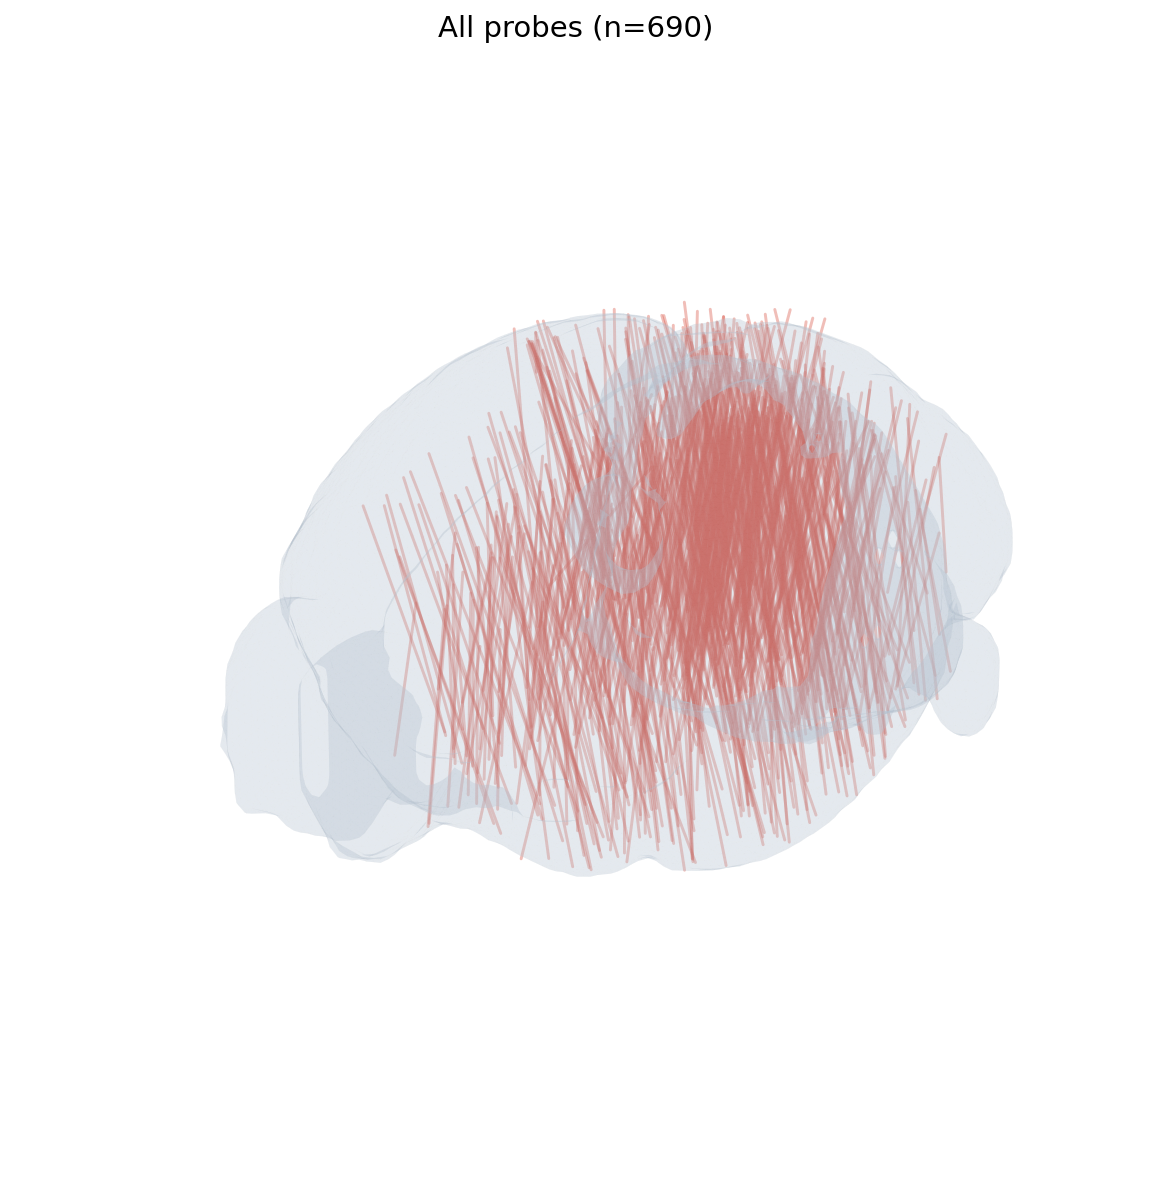

All probes: 690 probes


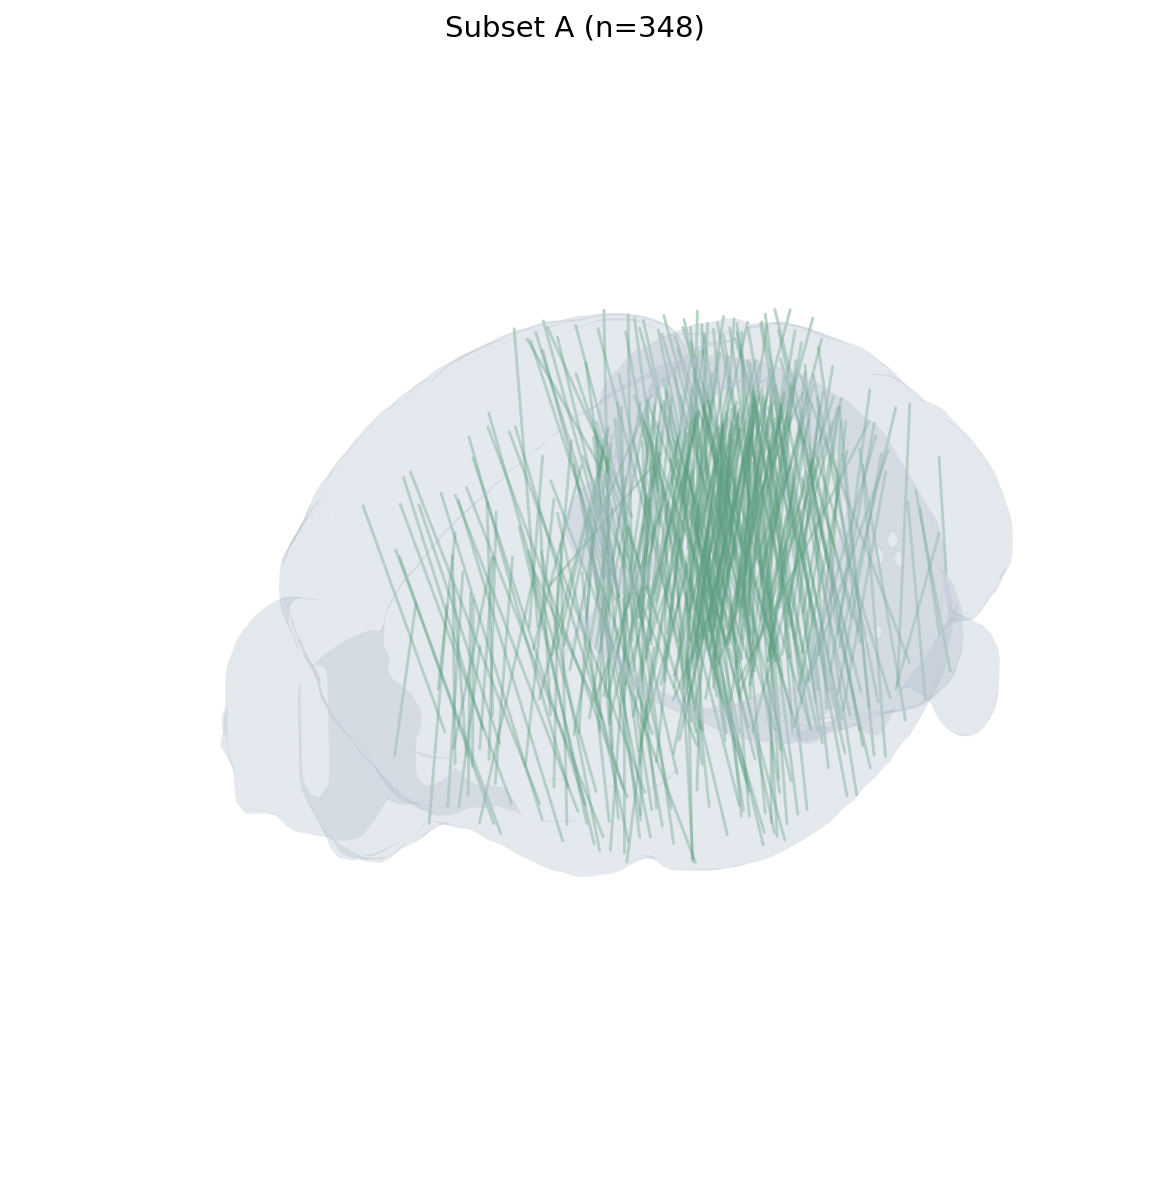

Subset A: 348 probes


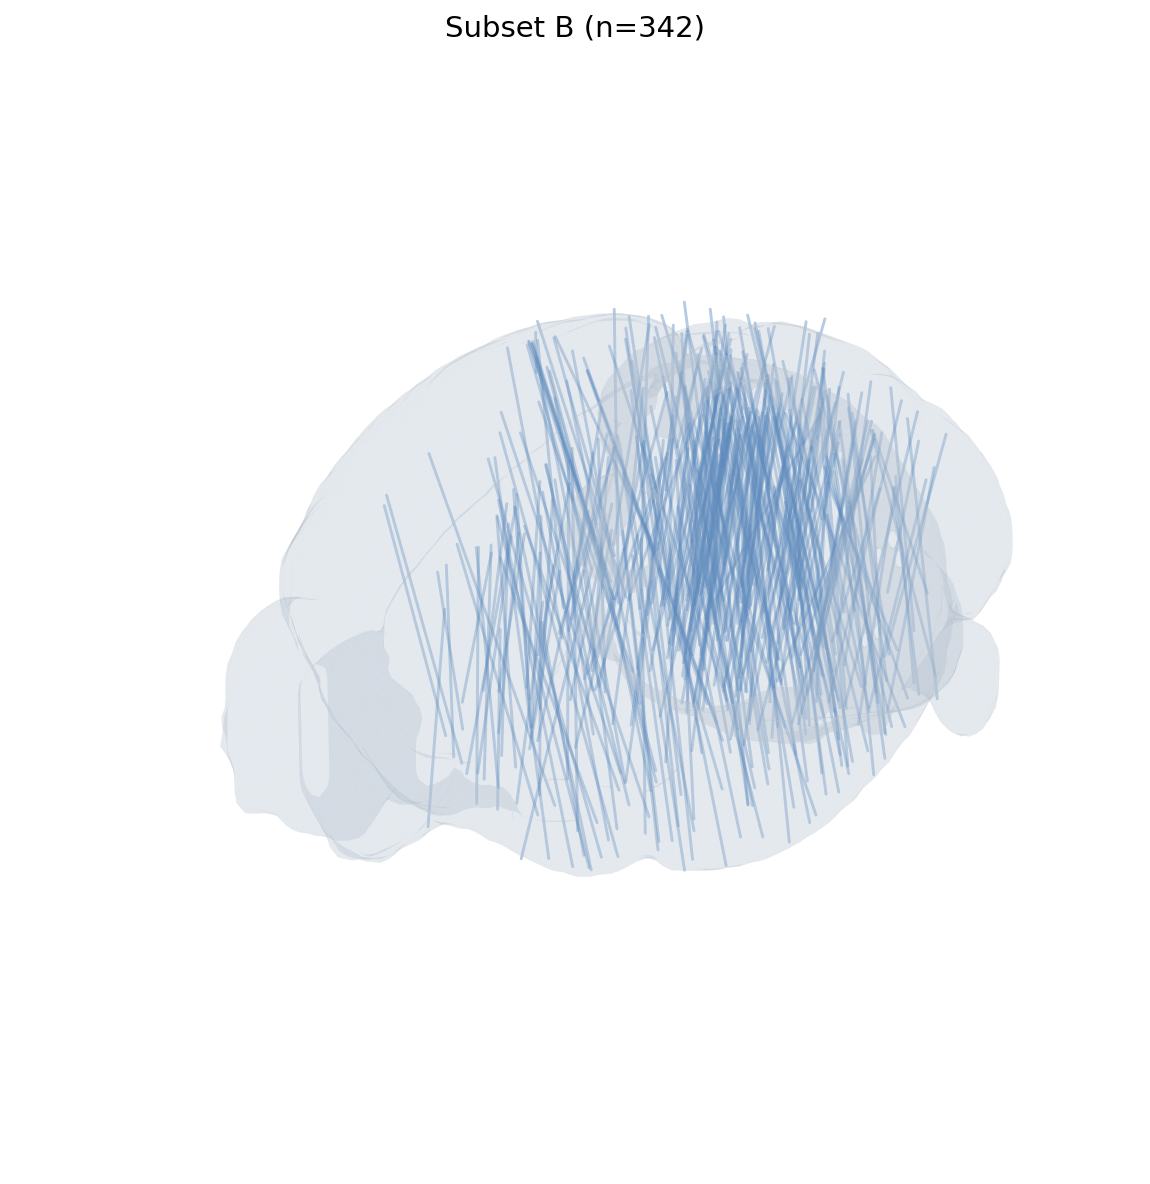

Subset B: 342 probes


In [7]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

from iblatlas.atlas import AllenAtlas
from scipy.ndimage import gaussian_filter
from skimage.measure import marching_cubes

ba = AllenAtlas()

STEP = 6
volume = (ba.label[::STEP, ::STEP, ::STEP] != 0).astype(np.float32)
volume = gaussian_filter(np.pad(volume, 1), sigma=0.7)

vertices, faces, _, _ = marching_cubes(volume, level=0.5)
indices = (vertices - 1) * STEP
brain_xyz = ba.bc.i2xyz(indices[:, ba.xyz2dims]) * 1e6

print(f'Brain mesh: {len(vertices)} vertices, {len(faces)} faces')

SEED = 22
COLORS = {'All': '#D64535', 'A': '#2E8B57', 'B': '#2F6DB3'}

unit_df = pd.read_csv('unit_df.csv')

with open(f'session_split_seed{SEED}.pkl', 'rb') as f:
    split = pickle.load(f)
with open(f'probe_tracks_seed{SEED}.pkl', 'rb') as f:
    tracks = pickle.load(f)

groups = {g: set(split[f'subset_{g}_eids']) for g in 'AB'}
df = unit_df[['eid', 'pid']].dropna().drop_duplicates('pid').copy()
df['pid'] = df['pid'].astype(str)
df['Group'] = df['eid'].map(
    lambda x: 'A' if x in groups['A'] else 'B' if x in groups['B'] else None
)
df = df.dropna(subset=['Group'])

mins, maxs = brain_xyz.min(axis=0), brain_xyz.max(axis=0)

def draw(pids, title, color):
    fig = plt.figure(figsize=(10, 8), dpi=150)
    ax = fig.add_subplot(111, projection='3d')

    ax.add_collection3d(Poly3DCollection(
        brain_xyz[faces], facecolor='#B8C5D3',
        edgecolor='none', alpha=0.2, zsort='average'
    ))

    n = 0
    for pid in pids:
        xyz = tracks.get(str(pid))
        if xyz is None:
            continue
        xyz = np.asarray(xyz)
        if xyz.ndim != 2 or xyz.shape[1] != 3:
            continue
        xyz = np.asarray(xyz, dtype=float)


        center = xyz.mean(axis=0)
        _, _, vh = np.linalg.svd(xyz - center, full_matrices=False)
        direction = vh[0]

        # Project all points onto the fitted line
        t = (xyz - center) @ direction
        line = np.array([
            center + t.min() * direction,
            center + t.max() * direction
        ])

        ax.plot(
            line[:, 0], line[:, 1], line[:, 2],
            color=color,
            lw=1.4,
            alpha=0.35,
            solid_capstyle='round'
        )
        n += 1

    ax.set(xlim=mins[[0]][0:1].tolist() + maxs[[0]].tolist(),
           ylim=(mins[1], maxs[1]), zlim=(mins[2], maxs[2]))
    ax.set_box_aspect(maxs - mins)
    ax.view_init(elev=25, azim=135)
    ax.set_axis_off()
    ax.set_title(f'{title} (n={n})', fontsize=14)
    plt.tight_layout()
    plt.show()
    print(f'{title}: {n} probes')

print(f'Total PIDs: {df.pid.nunique()}')
for group in ['All', 'A', 'B']:
    pids = df.pid if group == 'All' else df.loc[df.Group == group, 'pid']
    draw(pids.unique(), 'All probes' if group == 'All' else f'Subset {group}', COLORS[group])